In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 

# Load Titanic Dataset
url = r"E:\EDA WITH LLM\healthcare_titanic_practice_data.csv"
df = pd.read_csv(url)
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,1,1,"Allen, Mr. George",male,37.0,1,0,114248,40.2980,D13,S
1,2,1,1,"Allen, Mrs. Helen",female,37.1,0,0,PP 83397,140.0882,NaN,S
2,3,1,2,"Cumings, Mrs. Elizabeth",female,24.7,4,1,196264,19.5158,NaN,S
3,4,1,1,"West, Mr. James",male,52.1,0,0,PC 9675,79.4856,F100,C
4,5,0,3,"West, Master. Robert",male,NaN,1,0,A/8. 12915,16.4185,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
1495,1496,0,3,"Brown, Mme. Margaret",female,49.2,0,0,STON/O3. 3584,16.9652,NaN,C
1496,1497,0,3,"Smith, Mr. Frederick",male,31.0,0,2,STON/O2. 30633,10.8405,NaN,S
1497,1498,0,3,"Saundercock, Miss. Clara",female,NaN,2,0,PP 66059,12.7129,NaN,S
1498,1499,1,1,"Cumings, Mrs. Florence",female,31.6,0,0,PP 48772,17.6137,NaN,S


In [3]:
# Display dataset info 
print(df.describe())

       PassengerId     Survived       Pclass          Age        SibSp  \
count  1500.000000  1500.000000  1500.000000  1210.000000  1500.000000   
mean    750.500000     0.414667     2.342667    29.807190     0.478000   
std     433.157015     0.492829     0.824034    13.303378     0.902252   
min       1.000000     0.000000     1.000000     0.400000     0.000000   
25%     375.750000     0.000000     2.000000    20.900000     0.000000   
50%     750.500000     0.000000     3.000000    29.850000     0.000000   
75%    1125.250000     1.000000     3.000000    38.600000     1.000000   
max    1500.000000     1.000000     3.000000    71.100000     5.000000   

             Parch         Fare  
count  1500.000000  1500.000000  
mean      0.508667    28.025157  
std       1.028898    34.040802  
min       0.000000     3.000000  
25%       0.000000    10.707775  
50%       0.000000    17.117450  
75%       1.000000    29.996000  
max       6.000000   460.558100  


In [4]:
# Missing Values Checks
print("\n Missing Values Check :\n", df.isnull().sum())


 Missing Values Check :
 PassengerId       0
Survived          0
Pclass            0
Name              0
Sex               0
Age             290
SibSp             0
Parch             0
Ticket            0
Fare              0
Cabin          1116
Embarked         24
dtype: int64


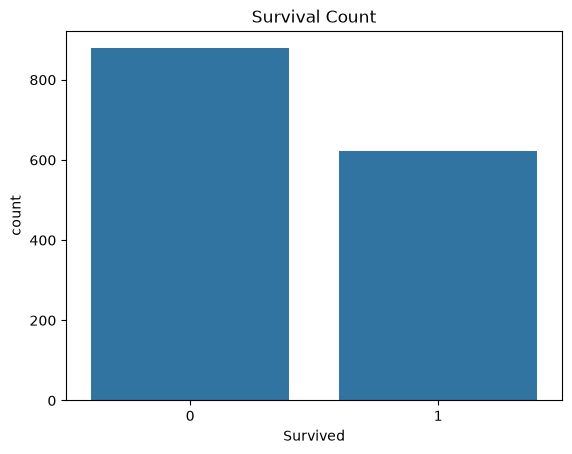

In [5]:
# Survival Rate Visualization
sns.countplot(x='Survived',data=df)
plt.title('Survival Count')
plt.show()

In [11]:
import ollama

def generate_insights(df_summary):
    prompt = f"Analyze the  dataset summary and provide insights:\n\n{df_summary}"
    response = ollama.chat(model = "mistral", messages = [{"role": "user", "content" : prompt}])
    return response ['message']['content']

# Generate AI Insights 
summary = df.describe().to_string()
insights = generate_insights(summary)
print("n AI-Generated Insights:\n", insights)

n AI-Generated Insights:
  The dataset appears to be the Titanic passenger data, which includes various features about the passengers such as their ID, survival status, travel class, age, number of siblings and parents on the ship, fare, and other details. Here are some insights based on the summary:

1. The dataset consists of 1500 rows and 7 columns. Each row represents a passenger.

2. The mean (average) Survived column is 0.414667, indicating that about 41.5% of passengers survived the sinking.

3. The mean age of passengers is 29.807190, suggesting a relatively younger passenger demographic.

4. The mean Pclass (travel class) is 2.342667, indicating that a majority of passengers were traveling in second class. This might be because the data is skewed towards passengers who boarded in Southampton, where second-class passengers were more numerous.

5. The standard deviation (std) for the Age column is 13.303378, showing a wide range in the ages of passengers.

6. The Fare column has

In [7]:
pip install pandas ollama


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
import ollama

def generate_insights(df_summary):
    prompt = f"Analyze the  dataset summary and provide insights:\n\n{df_summary}"
    response = ollama.chat(model = "mistral", messages= [{"role": "user", "content" : prompt}])
    return response ['message']['content']

# Generate AI Insights 
summary = df.describe().to_string()
insights = generate_insights(summary)
print("AI-Generated Insights:\n", insights)

AI-Generated Insights:
  The dataset appears to be the Titanic passenger data, containing information about 1500 passengers on the Titanic. Here are some insights based on the summary:

1. **PassengerId**: Unique ID for each passenger.

2. **Survived**: Binary variable indicating whether the passenger survived (1) or not (0). The mean value of 0.414667 suggests that approximately 41.5% of passengers survived.

3. **Pclass**: Indicates the class of the passenger (1st, 2nd, 3rd). The mean value of 2.342667 suggests most passengers were traveling in 2nd class.

4. **Age**: Age of the passenger. The mean age is 29.807190, with a standard deviation of 13.303378, suggesting a wide range of ages among passengers.

5. **SibSp**: Number of siblings or spouses aboard the Titanic. The mean value of 0.478000 suggests that on average, a passenger had slightly less than half a sibling or spouse on the ship.

6. **Parch**: Number of parents or children aboard the Titanic. The mean value of 0.508667 s

In [38]:
pip install gradio


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import pandas as pd
import gradio as gr

# Function to generate AI insights
def generate_insights(df_summary):

    prompt = f"""
    Analyze this dataset summary and provide:
    1. Important observations
    2. Data trends
    3. Missing values insights
    4. Business recommendations

    Dataset Summary:
    {df_summary}
    """

    response = ollama.chat(
        model="mistral",
        messages=[
            {"role": "user", "content": prompt}
        ]
    )

    return response["message"]["content"]


# Function for EDA analysis
def eda_analysis(file):

    try:
        # Read uploaded CSV
        df = pd.read_csv(file)

        # Generate summary
        summary = df.describe(include="all").to_string()

        # Generate AI insights
        insights = generate_insights(summary)

        return summary, insights

    except Exception as e:
        return "Error occurred", str(e)


# Create Gradio Interface OUTSIDE the function
demo = gr.Interface(
    fn=eda_analysis,
    inputs=gr.File(
        label="Upload CSV Dataset",
        file_types=[".csv"],
        type="filepath"
    ),
    outputs=[
        gr.Textbox(label="Dataset Summary", lines=15),
        gr.Textbox(label="AI Generated Insights", lines=15)
    ],
    title="AI-Powered EDA with Mistral",
    description="Upload a CSV file to generate automatic data analysis and AI insights."
)


# Launch Gradio Application
if __name__ == "__main__":
    demo.launch(share=True)


* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://6af81dcd1d47c9b36c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
